# 🔭 Lesson 4: Principal Component Analysis (PCA)
### *"Your data has 14 columns. Your screen has 2 dimensions. Now what?"*

**Week 10 · Session 4 of 6 · ⏱ about 2 hours**

---

### 🎯 Learning objectives
By the end of this lesson you will be able to:
1. Explain PCA as *"finding the directions of greatest variation"*.
2. Compute PCA **from scratch** (covariance → eigenvectors) and verify with scikit-learn.
3. Choose the number of components using **explained variance** and a **scree plot**.
4. **Interpret** components through their *loadings*.
5. Use PCA for **visualisation, compression, denoising, feature extraction, and building indices**.
6. Know PCA's limits and when to reach for **t-SNE/UMAP**.

### 📋 Prerequisites
Lessons 1–3, plus: mean, variance, correlation, and (lightly) matrices. No linear-algebra degree required!

## 1 · The story: the photographer's problem 📷

You're photographing a **banana** with a camera that can only record **2-D photos** of a **3-D object**. 

- Photograph it end-on and you get a small circle. You can't tell it's a banana! Most of the *information* (its length and curve) was lost.
- Photograph it from the side and you capture the long curved shape. Nearly everything is preserved.

**Choosing the best camera angle = choosing the direction that preserves the most information.** That's PCA.

In data terms:
- Each **column** is a dimension.
- *Information* ≈ **variation** (spread). A column where every farmer has the same value tells you nothing.
- PCA finds the new axes (the **principal components** (PCs)) along which the data varies the *most*, ordered from most to least.
- Keep the first few PCs; drop the rest. You've compressed, say, **9 columns → 3**, losing only a little.

> 💡 **Intuition.** PCA **rotates** your coordinate system so that the first axis points along the longest stretch of the data cloud, the second along the next-longest *(at right angles to the first)*, and so on. Nothing is distorted; we just look from a smarter angle.

### Why would we want fewer dimensions?

| Reason | Example |
|---|---|
| 👀 **Visualise** | Plot 14-dimensional farmers on a 2-D chart |
| 🗜️ **Compress** | Store images, speed up algorithms |
| 🔇 **Denoise** | Small PCs are often just noise: drop them |
| 🧩 **Remove redundancy** | Fertiliser and yield are correlated, so one new axis can capture both |
| 📊 **Build indices** | One "development score" from ten market measures |
| 🛟 **Help other algorithms** | K-Means/DBSCAN behave better in fewer dimensions |

## 2 · See it in 2-D first 👁️

Take two correlated columns: **fertiliser use** and **yield**. Farmers who apply more fertiliser tend to get higher yields, so the cloud is a tilted ellipse.

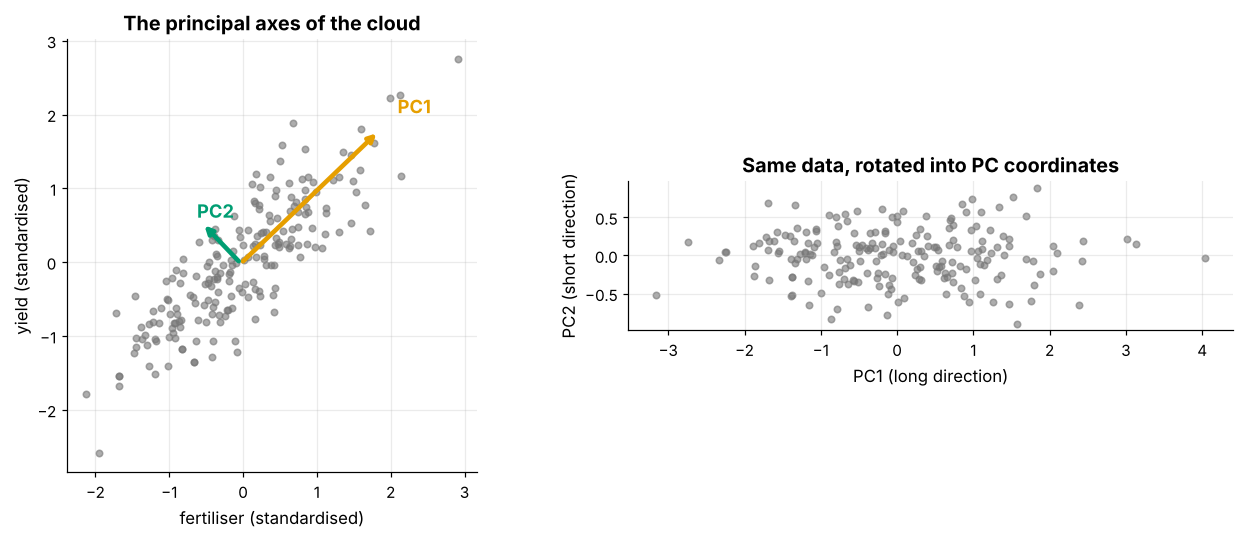

Variance explained by PC1 and PC2: [0.922 0.078]


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits
from sklearn.metrics import adjusted_rand_score
from course_utils import set_style, load, check, PALETTE
set_style()
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)
fert = rng.normal(0, 1, 200)
yld = 0.85 * fert + rng.normal(0, 0.45, 200)        # correlated with fertiliser
X2 = np.column_stack([fert, yld])                    # (already centred, roughly standardised)

pca2 = PCA(n_components=2).fit(X2)
mean = X2.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
ax.scatter(*X2.T, s=18, alpha=.6, color="#777")
for i, (comp, var) in enumerate(zip(pca2.components_, pca2.explained_variance_)):
    ax.annotate("", xy=mean + 2.2 * np.sqrt(var) * comp, xytext=mean, arrowprops=dict(arrowstyle="->", lw=3, color=PALETTE[i + 1]))
    ax.text(*(mean + 2.5 * np.sqrt(var) * comp), f"PC{i + 1}", color=PALETTE[i + 1], fontweight="bold", fontsize=12)
ax.set_aspect("equal"); ax.set_xlabel("fertiliser (standardised)"); ax.set_ylabel("yield (standardised)"); ax.set_title("The principal axes of the cloud")

ax = axes[1]
Z2 = pca2.transform(X2)
ax.scatter(Z2[:, 0], Z2[:, 1], s=18, alpha=.6, color="#777")
ax.set_aspect("equal"); ax.set_xlabel("PC1 (long direction)"); ax.set_ylabel("PC2 (short direction)"); ax.set_title("Same data, rotated into PC coordinates")
plt.tight_layout(); plt.show()
print("Variance explained by PC1 and PC2:", pca2.explained_variance_ratio_.round(3))

**Left:** the arrows are the principal components; PC1 runs along the long axis of the ellipse; PC2 is perpendicular. The arrow length shows how much spread there is in that direction. 
**Right:** *the same points*, but we've rotated the picture so PC1 is horizontal. Notice the cloud is now wide and flat. Almost all the variation is along PC1.

If we threw away PC2 (the vertical axis) we'd squash everything onto a line: losing only the small up-down wiggle. That's **dimensionality reduction**: 2 columns → 1 with little loss.

## 3 · The math, gently 📐

**Step 1: Centre.** Subtract each column's mean (so the cloud is centred at the origin). 

**Step 2: Covariance matrix.** For $p$ columns, build the $p \times p$ matrix $C$ whose entries are the covariances between every pair of columns. (Diagonal = variances. When the columns are standardised, $C$ is the *correlation* matrix.)

**Step 3: Eigen-decomposition.** Find the **eigenvectors** and **eigenvalues** of $C$:

$$ C\,\mathbf{v}_k = \lambda_k\,\mathbf{v}_k $$

- Each **eigenvector** $\mathbf{v}_k$ is a *direction*: a principal component. It's a list of $p$ weights ("loadings"), one per original column.
- Each **eigenvalue** $\lambda_k$ is *the variance of the data along that direction*.
- Sort so $\lambda_1 \ge \lambda_2 \ge \dots$

**Step 4: Project.** The new coordinates ("scores") are just dot products: $\;Z = X_c\,V$ where $V$ holds the eigenvectors as columns. Keep only the first $m$ columns of $Z$.

**Explained variance ratio** of component $k$: 

$$ \frac{\lambda_k}{\lambda_1 + \dots + \lambda_p} $$

> 🧠 **Remember.** Eigenvectors tell you *where* to look. Eigenvalues tell you *how much there is to see* there.

Let's build it. ✏️

In [2]:
def pca_scratch(X, n_components):
    """PCA from scratch via the covariance matrix."""
    X = np.asarray(X, float)
    mean = X.mean(axis=0)
    Xc = X - mean                                         # Step 1: centre
    cov = np.cov(Xc, rowvar=False)                        # Step 2: covariance matrix (p x p)
    eigvals, eigvecs = np.linalg.eigh(cov)                # Step 3: eigh = eigen-decomposition for symmetric matrices
    order = np.argsort(eigvals)[::-1]                     # sort from largest variance to smallest
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    components = eigvecs[:, :n_components].T              # each ROW is one principal direction
    scores = Xc @ components.T                            # Step 4: project
    return scores, components, eigvals, mean

scores, comps, eigvals, mu = pca_scratch(X2, 2)
print("our eigenvalues     :", eigvals.round(4))
print("scikit-learn        :", pca2.explained_variance_.round(4))
print("components match up to sign?", np.allclose(np.abs(comps), np.abs(pca2.components_)))

our eigenvalues     : [1.3843 0.1177]
scikit-learn        : [1.3843 0.1177]
components match up to sign? True


> ⚠️ **Watch out.** **Signs are arbitrary.** If $\mathbf{v}$ is an eigenvector, so is $-\mathbf{v}$. So your PC1 may point "the other way" compared with a textbook or a friend's notebook. That's normal. The *directions* are the same; interpret the loadings *relative* to each other, and flip the sign yourself if needed.

## 4 · Scale first: always (almost) ⚖️

PCA looks for **variance**. A column measured in millions has astronomically more variance than one in tens, so the biggest-number column would capture PC1 all by itself. Same lesson as K-Means, same cure: **standardise**.

Proof, with the farmers (including `annual_revenue_kes`, which is in the millions):

In [3]:
farmers = load("farmers")
prod_cols = ["farm_size_acres", "yield_bags_per_acre", "fertilizer_kg_per_acre", "irrigated", "labour_days_per_acre",
             "improved_seed", "coop_member", "distance_to_market_km", "post_harvest_loss_pct"]

raw = farmers[prod_cols + ["annual_revenue_kes"]]
raw = raw.fillna(raw.median())
print("Unscaled PCA: variance explained by PC1 =", f"{PCA().fit(raw).explained_variance_ratio_[0]:.4%}")
print("-> PC1 is just 'annual_revenue_kes'. The other nine columns were drowned out.")

Unscaled PCA: variance explained by PC1 = 100.0000%
-> PC1 is just 'annual_revenue_kes'. The other nine columns were drowned out.


## 5 · Worked example 🌾: Understanding farmers in fewer dimensions

We use the nine production features from Lesson 1 (`log1p` on farm size, median-fill the gaps, standardise). 

### Step 1: How many components do we need?
Plot the **scree plot** (variance per component) and the **cumulative explained variance**.

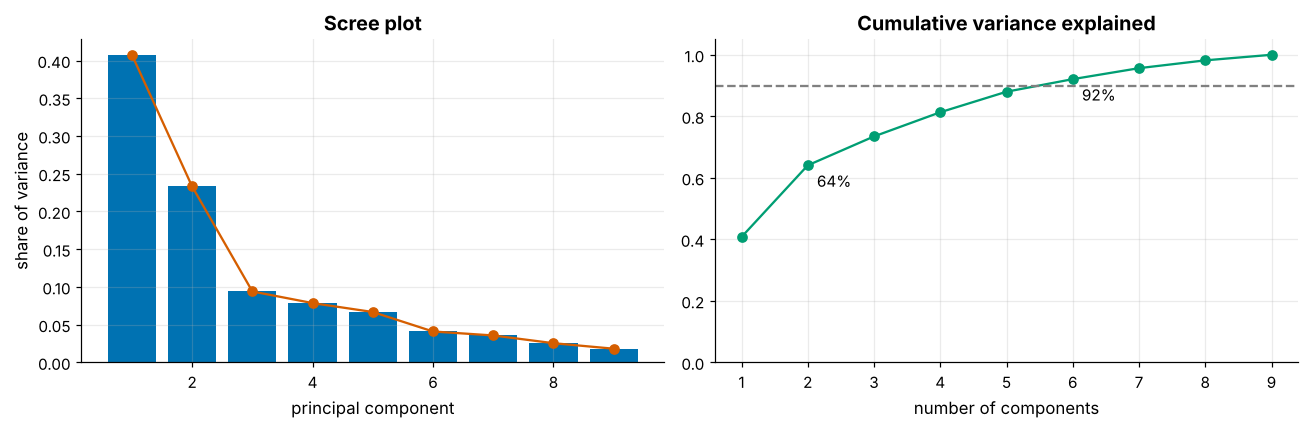

components needed for 90% of the variance: 6


In [4]:
Xf = farmers[prod_cols].copy()
Xf = Xf.fillna(Xf.median())
Xf["farm_size_acres"] = np.log1p(Xf["farm_size_acres"])
Xf_scaled = StandardScaler().fit_transform(Xf)

pca = PCA().fit(Xf_scaled)                      # keep ALL components first, then decide
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(evr) + 1), evr, color="#0072B2")
axes[0].plot(range(1, len(evr) + 1), evr, "o-", color="#D55E00")
axes[0].set_title("Scree plot"); axes[0].set_xlabel("principal component"); axes[0].set_ylabel("share of variance")
axes[1].plot(range(1, len(cum) + 1), cum, "o-", color="#009E73"); axes[1].axhline(0.9, ls="--", color="grey")
axes[1].set_title("Cumulative variance explained"); axes[1].set_xlabel("number of components"); axes[1].set_ylim(0, 1.05)
for k in (2, 6): axes[1].annotate(f"{cum[k-1]:.0%}", (k, cum[k - 1]), textcoords="offset points", xytext=(6, -14))
plt.tight_layout(); plt.show()
print("components needed for 90% of the variance:", int(np.argmax(cum >= 0.90)) + 1)

**Three common rules for choosing the number of components $m$:**

| Rule | How |
|---|---|
| **Cumulative variance** | Keep enough to reach 80–95% (we need 6 for 90%) |
| **Scree elbow** | Keep components before the curve flattens |
| **Kaiser** | For *standardised* data, keep PCs with eigenvalue > 1 (they carry more than one original column's worth of variance) |
| **Purpose** | For a 2-D plot: 2. For a downstream model: choose by *its* performance |

Here the first two PCs hold **64%**: decent for a picture, not for compression. Nine columns are *not* very redundant (that's actually good news: each feature carries distinct information).

### Step 2: Interpret the components via **loadings**
A component is a recipe: *"0.43 × yield + 0.43 × fertiliser − 0.42 × losses + …"*. The weights are the **loadings** (`pca.components_`). Big absolute values = important for that component.

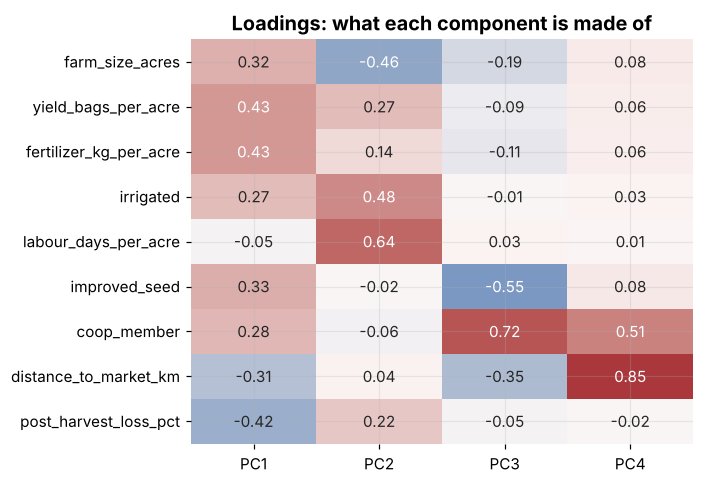

In [5]:
import seaborn as sns
loadings = pd.DataFrame(pca.components_[:4].T, index=prod_cols, columns=[f"PC{i}" for i in range(1, 5)])
plt.figure(figsize=(6.5, 4.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="vlag", center=0, cbar=False)
plt.title("Loadings: what each component is made of"); plt.tight_layout(); plt.show()

**Reading the heatmap** (signs may flip on your screen!):

- **PC1**: high weights on yield, fertiliser, improved seed, farm size, irrigation; negative on post-harvest loss and distance to market. → **"Commercial intensity / modernisation"**: farms that are productive, input-using, near markets and *lose less*.
- **PC2**: dominated by labour days per acre (+), irrigation (+), and farm size (−). → **"Labour-intensive small-plot horticulture"** vs "large mechanised farm".
- **PC3**: co-op membership vs improved seed / distance. → **"Social/co-operative organisation"**.

Naming components is *interpretation*, not mathematics, and it's one of the most valuable parts of PCA.

### Step 3: Visualise: farmers on a 2-D map 🗺️
Let's project to PC1 × PC2 and colour by K-Means clusters (from Lesson 1).

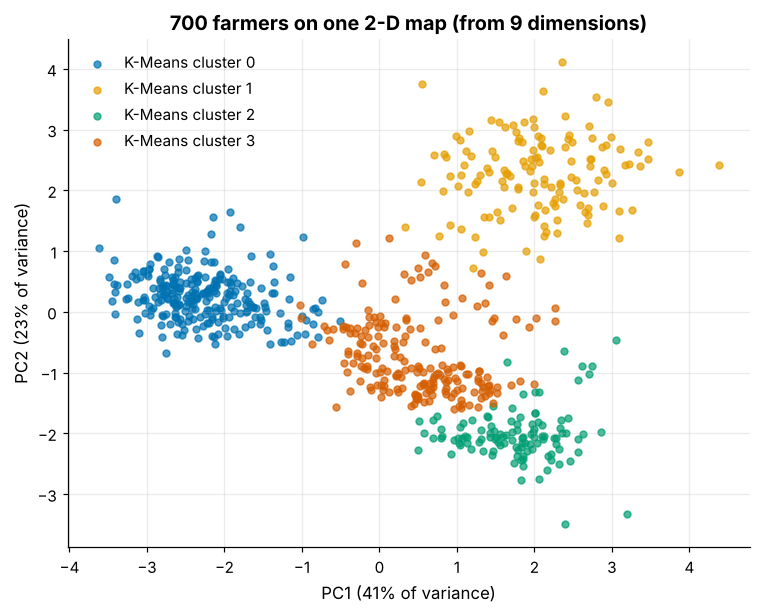

In [6]:
Z = pca.transform(Xf_scaled)[:, :2]
clusters = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit_predict(Xf_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
for c in range(4):
    ax.scatter(Z[clusters == c, 0], Z[clusters == c, 1], s=20, alpha=.7, label=f"K-Means cluster {c}", color=PALETTE[c])
ax.set_xlabel(f"PC1 ({evr[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({evr[1]:.0%} of variance)")
ax.set_title("700 farmers on one 2-D map (from 9 dimensions)"); ax.legend(); plt.show()

The four K-Means clusters (computed in all 9 dimensions) mostly appear as **distinct regions** in the 2-D PCA picture; the orange middle group overlaps its neighbours, which makes sense, since it is the transitional "emerging" type of farmer. This is the standard professional combo: **cluster in the full space, *visualise* with PCA**.

> ⚠️ **Watch out.** A 2-D PCA plot is a *shadow* of the data. Two clusters that overlap in the plot may still be perfectly separated in the dimensions you can't see. And the axes explain only 64% of variance: be humble about conclusions drawn from a picture.

## 6 · More applications 🧰

### 6a · Compression and reconstruction: handwritten digits ✍️
The classic: 8×8 pixel images of handwritten digits = **64 numbers** per image. How much of each image can we rebuild from just a handful of PCs?

The recipe: $\hat{X} = Z_m V_m^{\top} + \text{mean}$: **project down, then project back up**. `pca.inverse_transform(scores)` does exactly this.

digits: (1797, 64) -> 1,797 images x 64 pixels


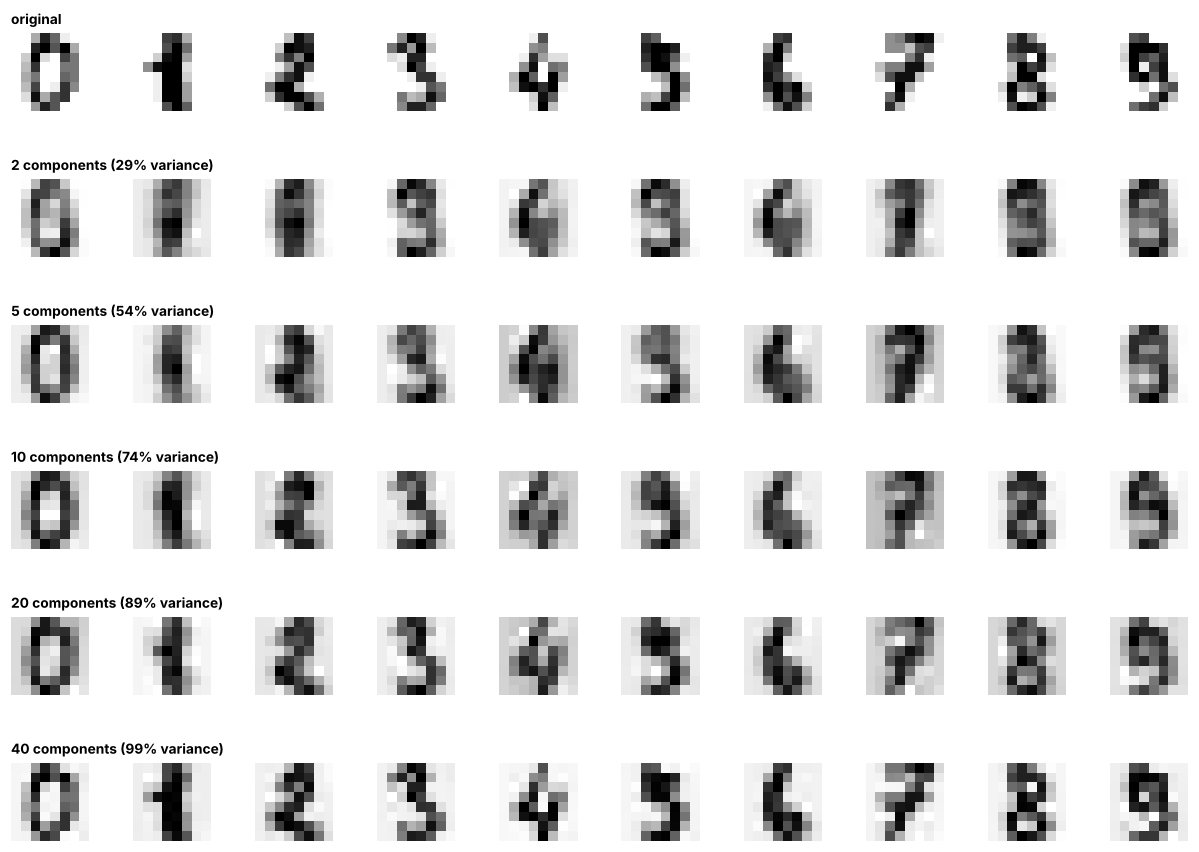

In [7]:
digits = load_digits()
Xd, yd = digits.data, digits.target
print("digits:", Xd.shape, "-> 1,797 images x 64 pixels")

ks = [2, 5, 10, 20, 40]
fig, axes = plt.subplots(len(ks) + 1, 10, figsize=(11, 8.2))
for j in range(10):
    axes[0, j].imshow(Xd[j].reshape(8, 8), cmap="gray_r"); axes[0, j].axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=9)
for i, k in enumerate(ks, start=1):
    p = PCA(k).fit(Xd)
    rec = p.inverse_transform(p.transform(Xd))
    for j in range(10):
        axes[i, j].imshow(rec[j].reshape(8, 8), cmap="gray_r"); axes[i, j].axis("off")
    axes[i, 0].set_title(f"{k} components ({p.explained_variance_ratio_.sum():.0%} variance)", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

With **2** components the digits are blurry blobs; by **20** (of 64) they're very legible; at **40** they're nearly perfect. We've compressed each image to **one third** of its size with almost no visible loss.

> 🌾 **Agricultural lens.** The same idea applies to **satellite imagery** (hundreds of spectral bands → a few PCs for crop-health mapping) and **soil spectroscopy** (thousands of wavelengths → a handful of components).

### 6b · Denoising 🔇
Noise is *random*, so it spreads thinly across all 64 directions, while the real signal concentrates in the top few. Keep only the top PCs and much of the noise vanishes.

PCA kept 37 of 64 components


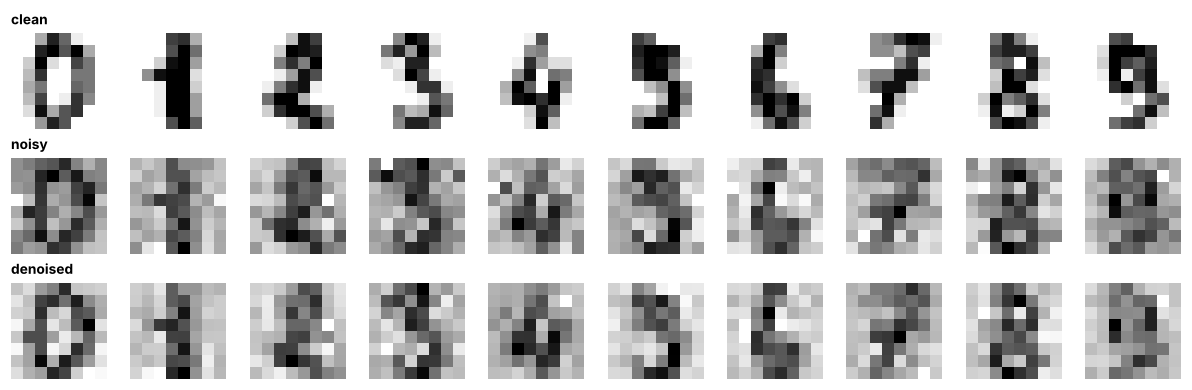

In [8]:
rng = np.random.default_rng(1)
noisy = Xd + rng.normal(0, 4, Xd.shape)                 # add heavy Gaussian noise
p = PCA(n_components=0.80).fit(noisy)                    # keep as many PCs as needed for 80% of variance
denoised = p.inverse_transform(p.transform(noisy))
print(f"PCA kept {p.n_components_} of 64 components")

fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
for r, (data, name) in enumerate([(Xd, "clean"), (noisy, "noisy"), (denoised, "denoised")]):
    for j in range(10):
        axes[r, j].imshow(data[j].reshape(8, 8), cmap="gray_r"); axes[r, j].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

### 6c · Feature extraction for other algorithms
PCA output can feed **any** downstream model or clustering. K-Means on the 64 raw digit pixels vs. on just 15 principal components:

In [9]:
import time
t0 = time.time(); km_raw = KMeans(10, n_init=10, random_state=0).fit(Xd); t_raw = time.time() - t0
Z15 = PCA(15).fit_transform(Xd)
t0 = time.time(); km_pca = KMeans(10, n_init=10, random_state=0).fit(Z15); t_pca = time.time() - t0

print(f"K-Means on 64 raw pixels : ARI vs true digits = {adjusted_rand_score(yd, km_raw.labels_):.3f}   ({t_raw:.2f}s)")
print(f"K-Means on 15 PCs        : ARI vs true digits = {adjusted_rand_score(yd, km_pca.labels_):.3f}   ({t_pca:.2f}s)")

K-Means on 64 raw pixels : ARI vs true digits = 0.666   (0.05s)
K-Means on 15 PCs        : ARI vs true digits = 0.663   (0.02s)


Same clustering quality, a quarter of the features, and faster. (K-Means never saw the labels; we peek at them only to score it.)

### 6d · Building an **index** from many measures 🏗️
Whenever you hear *"Human Development Index"*, *"Wealth Index"*, or *"Market Development Score"*, there's often a PCA behind it: **PC1 as a single composite score**.

Let's build a **Market Development Index** from the 10 market characteristics. First, how much does PC1 alone capture?

In [10]:
markets = load("markets")
market_cols = ["avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility", "distance_to_city_km", "road_quality_1_5",
               "has_cold_storage", "perishable_share", "n_commodities", "mobile_payment_share", "market_days_per_week"]
Xm = StandardScaler().fit_transform(markets[market_cols])
pm = PCA().fit(Xm)
print("PC1 explains", f"{pm.explained_variance_ratio_[0]:.0%}", "of all variation across 10 columns!")

load_m = pd.Series(pm.components_[0], index=market_cols)
if load_m["avg_daily_traders"] < 0:                       # sign fix: make 'higher score = more developed'
    load_m = -load_m
print(load_m.round(2).to_string())

PC1 explains 75% of all variation across 10 columns!
avg_daily_traders          0.33
avg_daily_volume_tonnes    0.34
price_volatility          -0.31
distance_to_city_km       -0.29
road_quality_1_5           0.33
has_cold_storage           0.24
perishable_share           0.29
n_commodities              0.33
mobile_payment_share       0.34
market_days_per_week       0.34


In [11]:
raw_score = Xm @ load_m.values
markets["development_index"] = 100 * (raw_score - raw_score.min()) / (raw_score.max() - raw_score.min())     # rescale to 0-100

print("Top 5:   ", markets.nlargest(5, "development_index")["market_name"].tolist())
print("Bottom 5:", markets.nsmallest(5, "development_index")["market_name"].tolist())

Top 5:    ['Mombasa Urban 2', 'Mombasa Urban 10', 'Mombasa Urban 1', 'Nakuru Urban 1', 'Meru Urban 9']
Bottom 5: ['Remote Rural 101', 'Remote Rural 103', 'Remote Rural 97', 'Remote Rural 99', 'Remote Rural 102']


Every positive-loading column (traders, volume, roads, mobile payments, cold storage…) pushes the index up; **volatility** and **distance to city** (negative loadings) push it down. Ten messy numbers → one interpretable 0–100 score, and the ranking makes sense: urban hubs on top, remote rural markets at the bottom.

> ⚠️ **Watch out.** Indices built by PCA are *data-driven*, not *policy-driven*: PC1 reflects whatever varies most. Always check the loadings make sense before publishing a score!

## 7 · Beyond PCA: t-SNE (a quick peek) 🪄

PCA is **linear**: it can only rotate and squash. Some data lives on **curved** surfaces that PCA flattens badly. **t-SNE** and **UMAP** are non-linear methods built for *visualisation*: they try to keep **neighbours** together in 2-D.

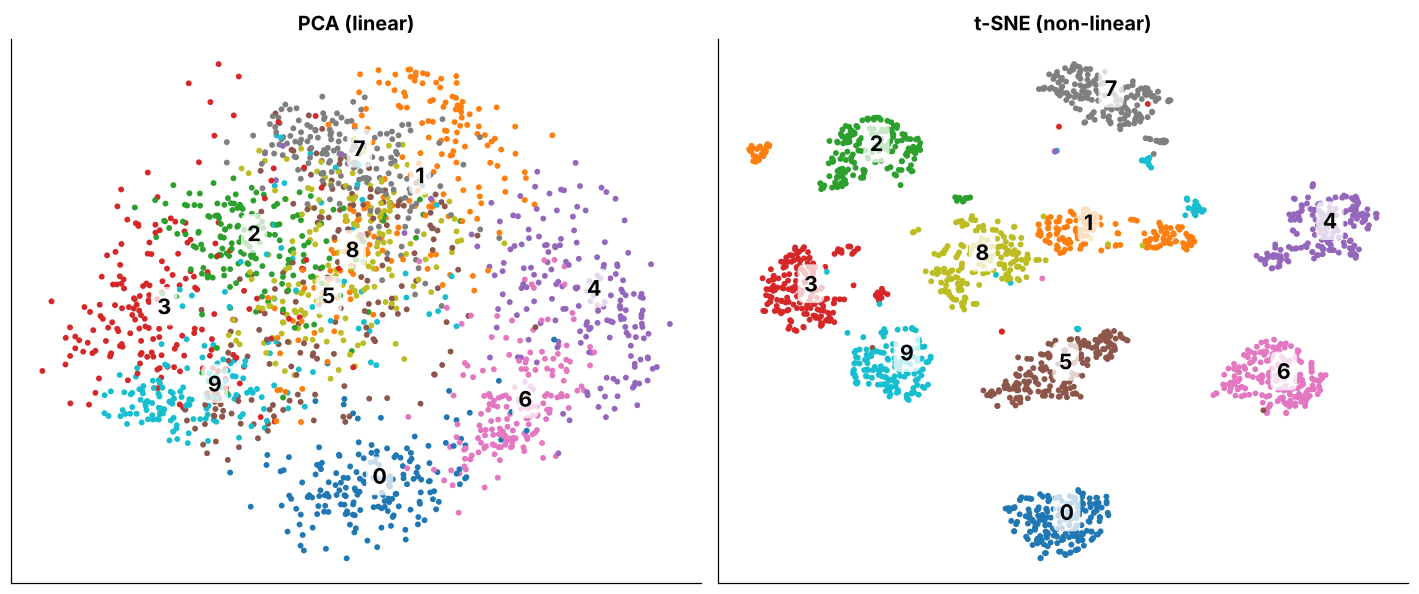

In [12]:
from sklearn.manifold import TSNE
Zp = PCA(2).fit_transform(Xd)
Zt = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, init="pca").fit_transform(Xd)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (Zv, name) in zip(axes, [(Zp, "PCA (linear)"), (Zt, "t-SNE (non-linear)")]):
    sc = ax.scatter(Zv[:, 0], Zv[:, 1], c=yd, cmap="tab10", s=8)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    for d in range(10):
        cx, cy = np.median(Zv[yd == d], axis=0); ax.text(cx, cy, str(d), fontsize=14, fontweight="bold",
                                                       bbox=dict(boxstyle="round", fc="white", alpha=.75, lw=0))
plt.tight_layout(); plt.show()

t-SNE separates the ten digits into crisp islands; PCA's 2-D shadow overlaps heavily. **But** use t-SNE with care:

| | **PCA** | **t-SNE / UMAP** |
|---|---|---|
| Type | Linear, deterministic | Non-linear, stochastic |
| Distances between far-apart clusters | Meaningful | **Not** meaningful |
| Cluster sizes in plot | Meaningful | **Not** meaningful |
| Can transform new data | ✅ | ❌ (t-SNE) |
| Good for | Preprocessing, compression, indices, interpretation | **Pictures only** |
| Speed | Very fast | Slow |

**Never run clustering on t-SNE coordinates and trust the cluster shapes.** Use it to *look*, not to *measure*.

## 8 · Pitfalls checklist ⚠️

1. **Forgetting to scale** → PC1 = your biggest-number column.
2. **Over-interpreting** a 2-D plot that explains only 40% of the variance.
3. **Assuming PCs are interpretable**; sometimes they're mixtures that defy simple names.
4. **Outliers**: PCA chases variance, so extreme points can hijack a component. Check/transform first.
5. **Categorical columns**: PCA needs numbers; one-hot columns work but are awkward.
6. **Train/test leakage**: fit the scaler and PCA on training data only, then `.transform()` new data.
7. **Low variance ≠ unimportant**: a small PC might be exactly the one that separates two classes (in supervised problems, check!).

## 9 · 🧩 Your turn: practice problems

### 🧩 Exercise 1: Eigenvalues by hand (almost)
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Here are 5 farms with two standardised measures:

```python
small = np.array([[-2.0, -1.8], [-1.0, -1.1], [0.0, 0.1], [1.0, 1.0], [2.0, 1.8]])
```

1. Compute the covariance matrix `cov` (use `np.cov(..., rowvar=False)`).
2. Compute its eigenvalues with `np.linalg.eigh`, sorted **largest first** → `eigvals_small`.
3. Compute `ratio_small` = the explained-variance **ratio** of each component (eigenvalue ÷ sum).

What do you conclude about how many dimensions these two measures really have?

<details><summary>💡 Hint 1</summary>

`cov = np.cov(small, rowvar=False)` is a 2×2 matrix.

</details>
<details><summary>💡 Hint 2</summary>

`np.linalg.eigh(cov)` returns eigenvalues in **ascending** order; reverse with `[::-1]`.

</details>
<details><summary>💡 Hint 3</summary>

`ratio_small = eigvals_small / eigvals_small.sum()`. The first value should be close to 1: the two measures are almost the same thing.

</details>

In [13]:
small = np.array([[-2.0, -1.8], [-1.0, -1.1], [0.0, 0.1], [1.0, 1.0], [2.0, 1.8]])
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('cov is 2x2', lambda: cov.shape == (2, 2))
check('eigenvalues sorted largest first', lambda: eigvals_small[0] >= eigvals_small[1])
check('ratios sum to 1', lambda: abs(ratio_small.sum() - 1) < 1e-9)
check('PC1 holds more than 99% of the variance', lambda: ratio_small[0] > 0.99)

### 🧩 Exercise 2: How many components do the farmers need?
**Difficulty:** ⭐  |  **Time:** ~7 min

Using `Xf_scaled` (already prepared):

1. Fit a full `PCA()` and compute the **cumulative** explained variance.
2. `n_comp_90` = smallest number of components reaching **≥ 90%**.
3. `n_comp_95` = smallest number reaching **≥ 95%**.
4. `kaiser_k` = number of components with **eigenvalue > 1** (`pca.explained_variance_`).

<details><summary>💡 Hint 1</summary>

`np.cumsum(pca.explained_variance_ratio_)`.

</details>
<details><summary>💡 Hint 2</summary>

`int(np.argmax(cum >= 0.90)) + 1`: `argmax` on a boolean array returns the index of the first `True` (index starts at 0, so add 1).

</details>
<details><summary>💡 Hint 3</summary>

`kaiser_k = int((pca.explained_variance_ > 1).sum())`.

</details>

In [15]:
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('90% needs 6 components', lambda: n_comp_90 == 6)
check('95% needs 7 components', lambda: n_comp_95 == 7)
check('Kaiser keeps 2 components', lambda: kaiser_k == 2)

### 🧩 Exercise 3: Interpret a component
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

Using the `loadings` DataFrame from Section 5, find:

- `pc2_top_feature`: the feature with the **largest absolute loading** on PC2
- `pc1_negative_features`: the **list of feature names** with a *negative* loading on PC1 *(note: sign flips are possible between runs of different libraries, so decide using the loadings you actually have: those whose sign is opposite to `yield_bags_per_acre`'s)*

Then write one sentence naming PC2 in plain language.

<details><summary>💡 Hint 1</summary>

`loadings['PC2'].abs().idxmax()` returns the row label of the largest absolute value.

</details>
<details><summary>💡 Hint 2</summary>

`np.sign(loadings['PC1'])` gives ±1. Compare with `np.sign(loadings.loc['yield_bags_per_acre', 'PC1'])` to find opposite-sign features.

</details>
<details><summary>💡 Hint 3</summary>

`loadings.index[mask].tolist()` converts a boolean mask into a list of names.

</details>

In [17]:
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('PC2 is dominated by labour days per acre', lambda: pc2_top_feature == 'labour_days_per_acre')
check('PC1 contrasts yield with losses and distance to market', lambda: {'post_harvest_loss_pct', 'distance_to_market_km'} <= set(pc1_negative_features))

### 🧩 Exercise 4: Compression: the cost of throwing components away
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

For the digits data `Xd` and each `k` in `[2, 5, 10, 20, 40]`:

1. Fit `PCA(k)`, reconstruct with `inverse_transform(transform(Xd))`.
2. Compute the **mean squared error** between `Xd` and the reconstruction.

Store the results in a dict `mse_by_k` (`{2: ..., 5: ..., ...}`). Then set `k_small_error` to the **smallest `k` in the list** whose MSE is **below 2.0**.

<details><summary>💡 Hint 1</summary>

`p = PCA(k).fit(Xd); rec = p.inverse_transform(p.transform(Xd))`

</details>
<details><summary>💡 Hint 2</summary>

`mse = ((Xd - rec) ** 2).mean()`

</details>
<details><summary>💡 Hint 3</summary>

`k_small_error = min(k for k, v in mse_by_k.items() if v < 2.0)`

</details>

In [19]:
mse_by_k = {}
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('error shrinks as k grows', lambda: all(mse_by_k[a] > mse_by_k[b] for a, b in [(2, 5), (5, 10), (10, 20), (20, 40)]))
check('20 components is the first to get below 2.0', lambda: k_small_error == 20)

### 🧩 Exercise 5: Build a Farm Intensification Index
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

Create a single score per farmer from the 9 production features, just as we did for markets.

1. `pc1_farm = PCA(1).fit(Xf_scaled)`; flip the sign if needed so that **yield has a positive loading**.
2. `farm_index` = the scores, rescaled to **0–100** (min → 0, max → 100), as a NumPy array of length 700.
3. `top_farmer_county` = the county of the farmer with the **highest** index.
4. `index_by_segment` = mean `farm_index` for each **true** segment (use `farmers_truth = load("farmers_truth")`: we peek at the hidden labels *only* to sanity-check our index).

<details><summary>💡 Hint 1</summary>

`scores = pc1_farm.transform(Xf_scaled).ravel()`; if `pc1_farm.components_[0, prod_cols.index('yield_bags_per_acre')] < 0: scores = -scores`.

</details>
<details><summary>💡 Hint 2</summary>

Rescale: `100 * (scores - scores.min()) / (scores.max() - scores.min())`.

</details>
<details><summary>💡 Hint 3</summary>

`farmers['county'].iloc[np.argmax(farm_index)]`. For (4): `pd.Series(farm_index).groupby(farmers_truth['true_segment']).mean()`.

</details>

In [21]:
farmers_truth = load("farmers_truth")
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('700 scores', lambda: len(farm_index) == 700)
check('scores span 0 to 100', lambda: abs(farm_index.min()) < 1e-9 and abs(farm_index.max() - 100) < 1e-9)
check('Intensive Horticulture scores far above Subsistence Smallholders', lambda: index_by_segment['Intensive Horticulture'] > index_by_segment['Subsistence Smallholder'] + 15)

### 🧩 Exercise 6: 🏆 Challenge: write your own PCA class
**Difficulty:** ⭐⭐⭐  |  **Time:** ~20 min

Write a class `MyPCA` with the scikit-learn interface:

- `__init__(self, n_components)`
- `fit(self, X)`: uses the **SVD** (`np.linalg.svd`) instead of the covariance matrix. Store `mean_`, `components_` (shape `n_components × p`), and `explained_variance_ratio_`.
- `transform(self, X)`: centre then project.
- `inverse_transform(self, Z)`: project back up and add the mean.

**SVD recipe.** For centred data $X_c$ (n rows), `U, S, Vt = np.linalg.svd(Xc, full_matrices=False)`. The rows of `Vt` are the principal directions; the eigenvalues of the covariance are `S**2 / (n - 1)`.

<details><summary>💡 Hint 1</summary>

`self.mean_ = X.mean(axis=0)`; `Xc = X - self.mean_`.

</details>
<details><summary>💡 Hint 2</summary>

`U, S, Vt = np.linalg.svd(Xc, full_matrices=False)`; `self.components_ = Vt[:self.n_components]`.

</details>
<details><summary>💡 Hint 3</summary>

`var = S ** 2 / (len(X) - 1)`; `self.explained_variance_ratio_ = (var / var.sum())[:self.n_components]`.

</details>
<details><summary>💡 Hint 4</summary>

`transform`: `(X - self.mean_) @ self.components_.T`;  `inverse_transform`: `Z @ self.components_ + self.mean_`.

</details>

In [23]:
class MyPCA:
    def __init__(self, n_components):
        self.n_components = n_components
    # YOUR CODE HERE (fit, transform, inverse_transform)

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('explained variance ratios match scikit-learn', lambda: np.allclose(MyPCA(3).fit(Xf_scaled).explained_variance_ratio_, PCA(3).fit(Xf_scaled).explained_variance_ratio_))
check('components match up to sign', lambda: np.allclose(np.abs(MyPCA(3).fit(Xf_scaled).components_), np.abs(PCA(3).fit(Xf_scaled).components_)))
check('full-rank round trip reproduces the data', lambda: np.allclose(MyPCA(9).fit(Xf_scaled).inverse_transform(MyPCA(9).fit(Xf_scaled).transform(Xf_scaled)), Xf_scaled))

### 🎯 Check your understanding
*Try to answer each question out loud or on paper before you peek.*

**Q1.** What does the first principal component represent?

<details><summary>Show answer</summary>

The **direction in feature space along which the data varies the most**. Every other component is perpendicular to the earlier ones and captures the most remaining variance.

</details>

**Q2.** A colleague runs PCA on raw farm data (acres, revenue in KES, yield in bags). PC1 explains 99.99% of variance. Is that a discovery?

<details><summary>Show answer</summary>

No, it's an **artefact of scale**: revenue is in the millions, so it dominates the variance. Standardise first (or work with correlations), then re-run.

</details>

**Q3.** What's the difference between an eigenvector and an eigenvalue in PCA?

<details><summary>Show answer</summary>

The **eigenvector** is a principal *direction* (the recipe of loadings). The **eigenvalue** is the *amount of variance* along that direction.

</details>

**Q4.** You keep 3 of 12 components and they explain 55% of the variance. Is that fine?

<details><summary>Show answer</summary>

It depends on the purpose. For a quick 3-D picture, maybe. For compression or as input to a model, 55% means a lot of information is lost: consider more components (e.g., 80–90%), or accept that the data really is high-dimensional.

</details>

**Q5.** Can we run PCA on a column like `county` (Nakuru, Meru, Kiambu…)?

<details><summary>Show answer</summary>

Not directly; PCA needs numeric columns where distances and variances mean something. You could one-hot encode, but a better approach for mixed data is often a different method (e.g., Gower distance + hierarchical clustering, or FAMD).

</details>

**Q6.** Why shouldn't you cluster t-SNE coordinates and interpret distances between clusters?

<details><summary>Show answer</summary>

t-SNE preserves *local neighbourhoods* but distorts global geometry: gaps, cluster sizes and inter-cluster distances in the picture are not reliable. Use it for *visualisation*, and cluster in the original (or PCA) space.

</details>

## 10 · Summary & cheat sheet 📝

| Concept | Remember |
|---|---|
| **PCA** | Rotate to the directions of maximum variance; keep the top few |
| **Steps** | Centre → covariance → eigen-decompose → project |
| **Eigenvector / eigenvalue** | Direction / variance along it |
| **Explained variance ratio** | $\lambda_k/\sum\lambda$; choose *m* via cumulative ≥ 80–95%, scree elbow, or purpose |
| **Loadings** | The recipe of each PC: how to name it |
| **Scale first!** | Otherwise PC1 = the biggest-number column |
| **Applications** | Visualise · compress · denoise · feature-extract · build indices |
| **Limits** | Linear only; outlier-sensitive; PCs may not be interpretable |

```python
from sklearn.decomposition import PCA
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=0.90).fit(X_scaled)        # a float = "keep enough PCs for 90% of the variance"
Z = pca.transform(X_scaled)
pca.explained_variance_ratio_, pca.components_    # how much / what each PC is made of
X_back = pca.inverse_transform(Z)                 # approximate reconstruction
```

### 🚀 Stretch ideas
- Run **K-Means on the first 3 PCs of the farmers** and compare with K-Means on all 9 features (ARI between the two).
- Try `KernelPCA` or `TruncatedSVD`; when would each be useful?
- Look up **UMAP** (`pip install umap-learn`) and compare with t-SNE on the digits.

### 📚 Next up
**Lesson 5: Association Rules:** switch from *rows* and *columns* to **baskets**: *"farmers who buy DAP fertiliser also buy hybrid maize seed. How often? How surprising?"* 🛒